In [1]:
# Core Data & Numerical Libraries
import pandas as pd
import numpy as np

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: Preprocessing, Pipelines, Splitting & Metrics
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
    average_precision_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
)

# Scikit-Learn: Linear & Tree-Based Regression Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
)
from sklearn.inspection import permutation_importance

# Gradient Boosted Tree Models
from xgboost import XGBClassifier, XGBRegressor

In [2]:
print("=" * 60)
print("STARTING STEP 1: LOAD & CLEAN DATA")
print("=" * 60)

# 1. Load Dataset & Initial Inspection
# The attached dataset is CSV-formatted even though its extension is .xls.
file_path = "Uber Drives - .xls"
if not pd.io.common.file_exists(file_path): # type: ignore
    file_path = "Uber Drives - .csv"
df = pd.read_csv(file_path)

print(f"\n[1] Initial Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
display(df.head())

# 2. Audit Data Types & Missing Values (Before Cleaning)
print("\n[2] Data Info & Missing Values Audit:")
missing_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2)
})
display(missing_summary[missing_summary["Missing Count"] > 0])

# 3. Drop Footer Summary Row ('Totals') & Exact Duplicates
initial_rows = len(df)
df = df.dropna(subset=["END_DATE*"]).reset_index(drop=True)
footer_dropped = initial_rows - len(df)

before_dedup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
dups_dropped = before_dedup - len(df)
print(f"\n[3] Rows Removed: {footer_dropped} footer ('Totals') row | {dups_dropped} exact duplicate row")

# 4. Clean Missing Values & City Typos
df["PURPOSE*"] = df["PURPOSE*"].fillna("Unknown")
df["START*"] = df["START*"].replace({"Kar?chi": "Karachi", "R?walpindi": "Rawalpindi"})
df["STOP*"] = df["STOP*"].replace({"Kar?chi": "Karachi", "R?walpindi": "Rawalpindi"})

# 5. Standardize Datetime Columns
df["START_DATE*"] = pd.to_datetime(df["START_DATE*"], errors="coerce")
df["END_DATE*"] = pd.to_datetime(df["END_DATE*"], errors="coerce")

# 6. Extract Temporal & Trip Features (Expanding to 15 columns)
df["Request Hour"] = df["START_DATE*"].dt.hour
df["Request Day"] = df["START_DATE*"].dt.day_name()
df["Request Month"] = df["START_DATE*"].dt.month_name()
df["Is_Weekend"] = df["START_DATE*"].dt.dayofweek.isin([5, 6]).astype(int)
df["Duration_mins"] = (df["END_DATE*"] - df["START_DATE*"]).dt.total_seconds() / 60.0
df["Speed_mph"] = np.where(df["Duration_mins"] > 0, df["MILES*"] / (df["Duration_mins"] / 60.0), 0.0)

def get_time_slot(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["Time Slot"] = df["Request Hour"].apply(get_time_slot)
df["Route"] = df["START*"] + " -> " + df["STOP*"]

# 7. Create Aggregated Demand Grid ('hourly_df')
hourly_df = (
    df.groupby("Request Hour")
    .agg(
        Total_Rides=("MILES*", "count"),
        Total_Miles=("MILES*", "sum"),
        Avg_Miles=("MILES*", "mean"),
        Avg_Duration_mins=("Duration_mins", "mean")
    )
    .reset_index()
)

# 8. Final Verification & Summary Output
print(f"\n[4] Remaining Missing Values: {df.isnull().sum().sum()}")
print("\n[5] Cleaned Numerical Summary:")
display(df.describe().T)

print("\n" + "=" * 60)
print("[SUCCESS] Dataset loaded and cleaned successfully.")
print(f" -> Total Processed Rows: {df.shape[0]:,} | Total Columns: {df.shape[1]}")
print(" -> Standardized Datetime Columns: 'START_DATE*', 'END_DATE*'")
print(" -> Extracted Features: 'Request Hour', 'Request Day', 'Duration_mins', 'Time Slot'")
print(f" -> Aggregated Demand Grid ('hourly_df'): {len(hourly_df)} hourly slots")
print("=" * 60)

print("STEP 1 COMPLETED SUCCESSFULLY")
print("=" * 60)
print(f" -> Main Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

STARTING STEP 1: LOAD & CLEAN DATA

[1] Initial Dataset Shape: 1,156 rows, 7 columns


,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit



[2] Data Info & Missing Values Audit:


,Data Type,Missing Count,Missing %
END_DATE*,object,1,0.09
CATEGORY*,object,1,0.09
START*,object,1,0.09
STOP*,object,1,0.09
PURPOSE*,object,503,43.51



[3] Rows Removed: 1 footer ('Totals') row | 1 exact duplicate row

[4] Remaining Missing Values: 0

[5] Cleaned Numerical Summary:


,count,mean,min,25%,50%,75%,max,std
START_DATE*,1154,2016-07-17 00:07:01.611784960,2016-01-01 21:11:00,2016-03-31 20:23:30,2016-07-21 17:29:30,2016-10-27 21:16:15,2016-12-31 22:08:00,NaN
END_DATE*,1154,2016-07-17 00:30:16.117850880,2016-01-01 21:17:00,2016-03-31 20:52:00,2016-07-21 17:37:00,2016-10-27 21:34:30,2016-12-31 23:51:00,NaN
MILES*,1154.0,10.567418,0.5,2.9,6.0,10.4,310.3,21.588452
Request Hour,1154.0,14.688908,0.0,12.0,15.0,18.0,23.0,4.570667
Is_Weekend,1154.0,0.258232,0.0,0.0,0.0,1.0,1.0,0.437852
Duration_mins,1154.0,23.241768,0.0,10.0,16.0,27.75,336.0,27.330072
Speed_mph,1154.0,26.717418,0.0,14.801299,21.0,28.363636,906.0,43.150795



[SUCCESS] Dataset loaded and cleaned successfully.
 -> Total Processed Rows: 1,154 | Total Columns: 15
 -> Standardized Datetime Columns: 'START_DATE*', 'END_DATE*'
 -> Extracted Features: 'Request Hour', 'Request Day', 'Duration_mins', 'Time Slot'
 -> Aggregated Demand Grid ('hourly_df'): 23 hourly slots
STEP 1 COMPLETED SUCCESSFULLY
 -> Main Dataset Shape: 1154 rows, 15 columns


In [3]:
print("=" * 60)
print("STARTING STEP 2: ADVANCED FEATURE ENGINEERING")
print("=" * 60)

# 1. Sanitize Trip Anomalies (Zero-Duration & Impossible Speeds)
# Cap unrealistic speeds (> 85 mph) and floor zero-minute durations to 1.0 min
initial_outliers = len(df[(df["Duration_mins"] <= 0) | (df["Speed_mph"] > 85)])
df["Duration_mins"] = df["Duration_mins"].clip(lower=1.0)
df["Speed_mph"] = (df["MILES*"] / (df["Duration_mins"] / 60.0)).clip(upper=85.0)
print(f"\n[1] Sanitized {initial_outliers} duration/speed anomalies (Max Speed capped at 85 mph)")

# 2. Cyclical Temporal Encoding & Traffic Window Flags
# Preserves circular continuity between 23:00 and 00:00
df["Hour_Sin"] = np.sin(2 * np.pi * df["Request Hour"] / 24.0)
df["Hour_Cos"] = np.cos(2 * np.pi * df["Request Hour"] / 24.0)
df["Day_Of_Week"] = df["START_DATE*"].dt.dayofweek
df["Is_Rush_Hour"] = df["Request Hour"].isin([8, 9, 17, 18, 19]).astype(int)

# 3. Spatial & Trip-Behavior Features
df["Is_Round_Trip"] = (df["START*"] == df["STOP*"]).astype(int)
df["Is_Unknown_Location"] = (
    (df["START*"] == "Unknown Location") | (df["STOP*"] == "Unknown Location")
).astype(int)

# Categorize trip distance into operational tiers
df["Distance_Tier"] = pd.cut(
    df["MILES*"],
    bins=[0, 3, 10, 25, np.inf],
    labels=["Short (<3 mi)", "Medium (3-10 mi)", "Long (10-25 mi)", "Intercity (>25 mi)"]
)

# Frequency encoding for high-cardinality locations & routes
start_freq = df["START*"].value_counts()
stop_freq = df["STOP*"].value_counts()
route_freq = df["Route"].value_counts()

df["Start_Location_Freq"] = df["START*"].map(start_freq)
df["Stop_Location_Freq"] = df["STOP*"].map(stop_freq)
df["Route_Popularity"] = df["Route"].map(route_freq)

# 4. Target Transformation (Log-Transform for Right-Skewed Targets)
# Useful for LinearRegression; tree models work well on raw or log targets
df["Log_Miles"] = np.log1p(df["MILES*"])
df["Log_Duration"] = np.log1p(df["Duration_mins"])

# 5. Enrich Aggregated Demand Grid ('hourly_df') for Demand Forecasting
# Fill any missing hour slot (0-23) so rolling windows stay continuous
all_hours = pd.DataFrame({"Request Hour": range(24)})
hourly_df = all_hours.merge(hourly_df, on="Request Hour", how="left").fillna(0)

hourly_df["Lag_1hr_Rides"] = hourly_df["Total_Rides"].shift(1).bfill()
hourly_df["Rolling_3hr_Avg_Rides"] = (
    hourly_df["Total_Rides"].rolling(window=3, min_periods=1).mean().round(2)
)
hourly_df["Demand_Share_%"] = (
    (hourly_df["Total_Rides"] / hourly_df["Total_Rides"].sum()) * 100
).round(2)

# 6. Verification & Summary Output
new_features = [
    "Hour_Sin", "Hour_Cos", "Day_Of_Week", "Is_Rush_Hour",
    "Is_Round_Trip", "Is_Unknown_Location", "Distance_Tier",
    "Start_Location_Freq", "Stop_Location_Freq", "Route_Popularity",
    "Log_Miles", "Log_Duration"
]

print(f"\n[2] Engineered {len(new_features)} new trip-level features:")
for feat in new_features:
    print(f"    - {feat}")

print("\n[3] Updated Numerical Feature Preview:")
display(df[["MILES*", "Duration_mins", "Speed_mph", "Is_Rush_Hour", "Is_Round_Trip", "Route_Popularity"]].head())

print("\n[4] Enriched Hourly Demand Grid ('hourly_df'):")
display(hourly_df.head(8))

print("\n" + "=" * 60)
print("STEP 2 COMPLETED SUCCESSFULLY")
print(f" -> Main Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f" -> Hourly Demand Grid: {hourly_df.shape[0]} rows, {hourly_df.shape[1]} columns")
print("=" * 60)

STARTING STEP 2: ADVANCED FEATURE ENGINEERING

[1] Sanitized 22 duration/speed anomalies (Max Speed capped at 85 mph)

[2] Engineered 12 new trip-level features:
    - Hour_Sin
    - Hour_Cos
    - Day_Of_Week
    - Is_Rush_Hour
    - Is_Round_Trip
    - Is_Unknown_Location
    - Distance_Tier
    - Start_Location_Freq
    - Stop_Location_Freq
    - Route_Popularity
    - Log_Miles
    - Log_Duration

[3] Updated Numerical Feature Preview:


,MILES*,Duration_mins,Speed_mph,Is_Rush_Hour,Is_Round_Trip,Route_Popularity
0,5.1,6.0,51.000000,0,1,4
1,5.0,12.0,25.000000,0,1,4
2,4.8,13.0,22.153846,0,1,4
3,4.7,14.0,20.142857,1,1,4
4,63.7,67.0,57.044776,0,0,1



[4] Enriched Hourly Demand Grid ('hourly_df'):


,Request Hour,Total_Rides,Total_Miles,Avg_Miles,Avg_Duration_mins,Lag_1hr_Rides,Rolling_3hr_Avg_Rides,Demand_Share_%
0,0,19.0,102.0,5.368421,13.894737,19.0,19.00,1.65
1,1,5.0,41.8,8.360000,18.400000,19.0,12.00,0.43
2,2,2.0,165.3,82.650000,73.500000,5.0,8.67,0.17
3,3,3.0,55.2,18.400000,25.000000,2.0,3.33,0.26
4,4,0.0,0.0,0.000000,0.000000,3.0,1.67,0.00
5,5,4.0,36.4,9.100000,14.750000,0.0,2.33,0.35
6,6,4.0,56.2,14.050000,23.000000,4.0,2.67,0.35
7,7,13.0,161.0,12.384615,23.846154,4.0,7.00,1.13



STEP 2 COMPLETED SUCCESSFULLY
 -> Main Dataset Shape: 1154 rows, 27 columns
 -> Hourly Demand Grid: 24 rows, 8 columns


STARTING STEP 3: EXPLORATORY DATA ANALYSIS (12 CHARTS TOTAL)


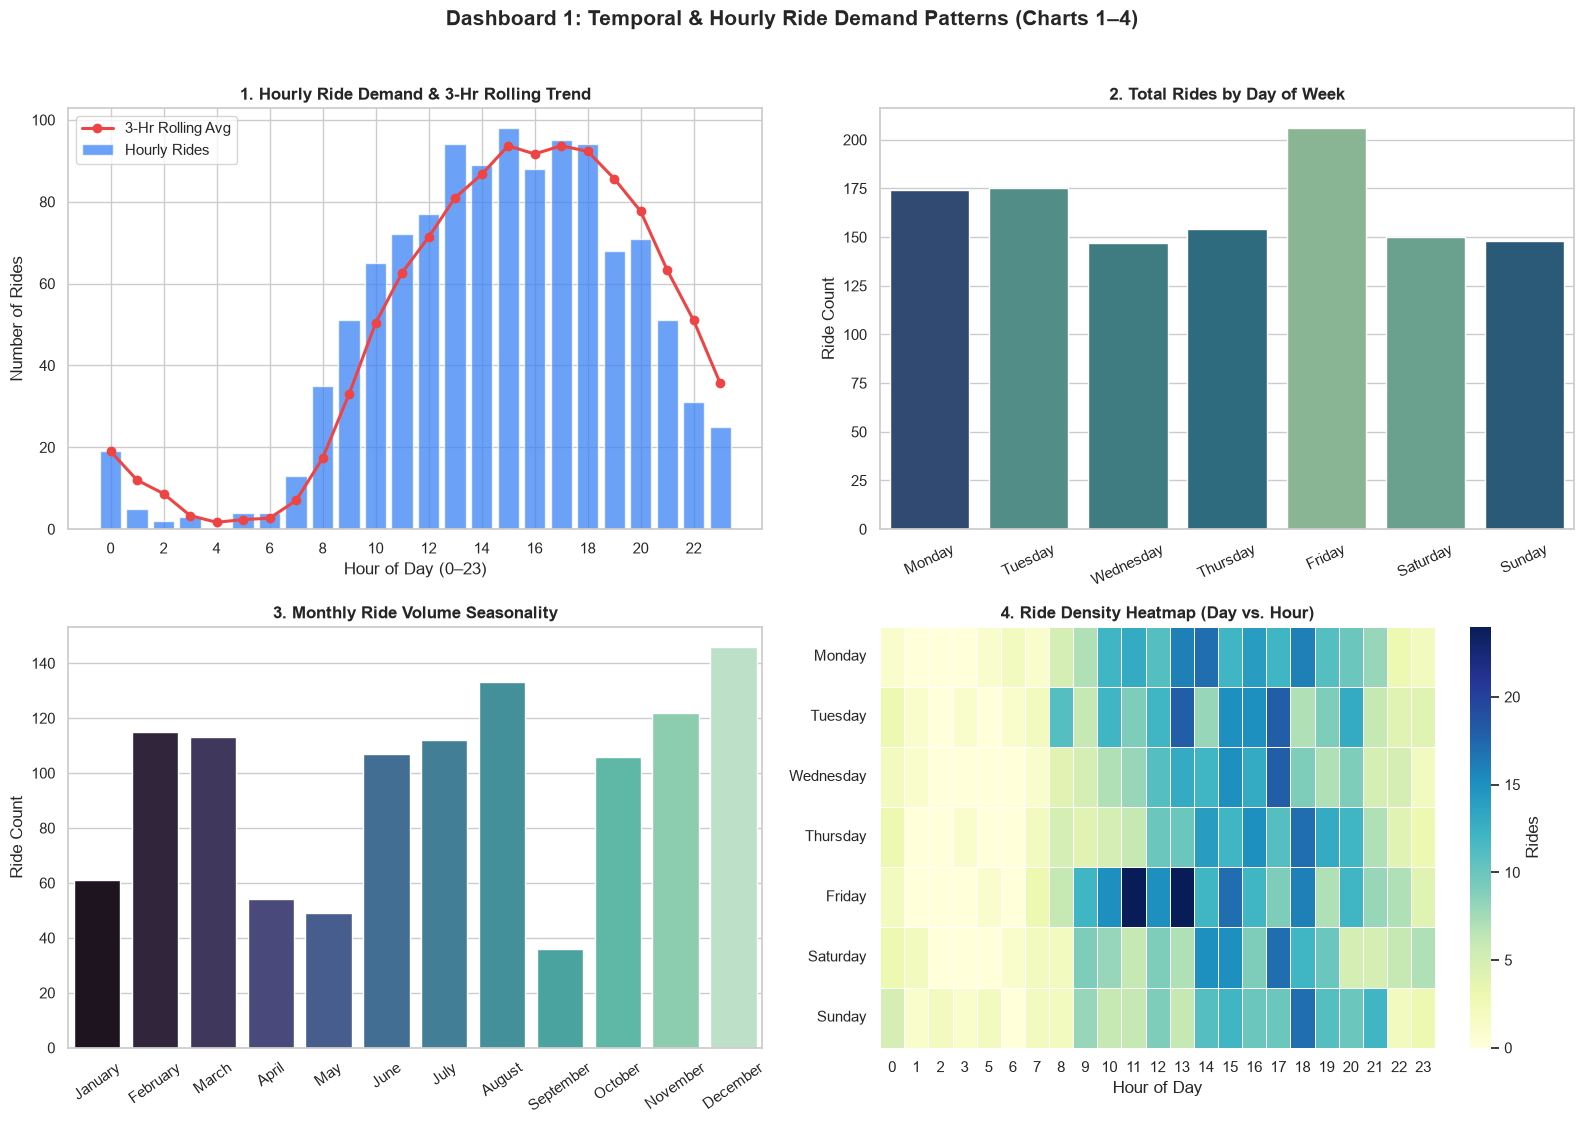

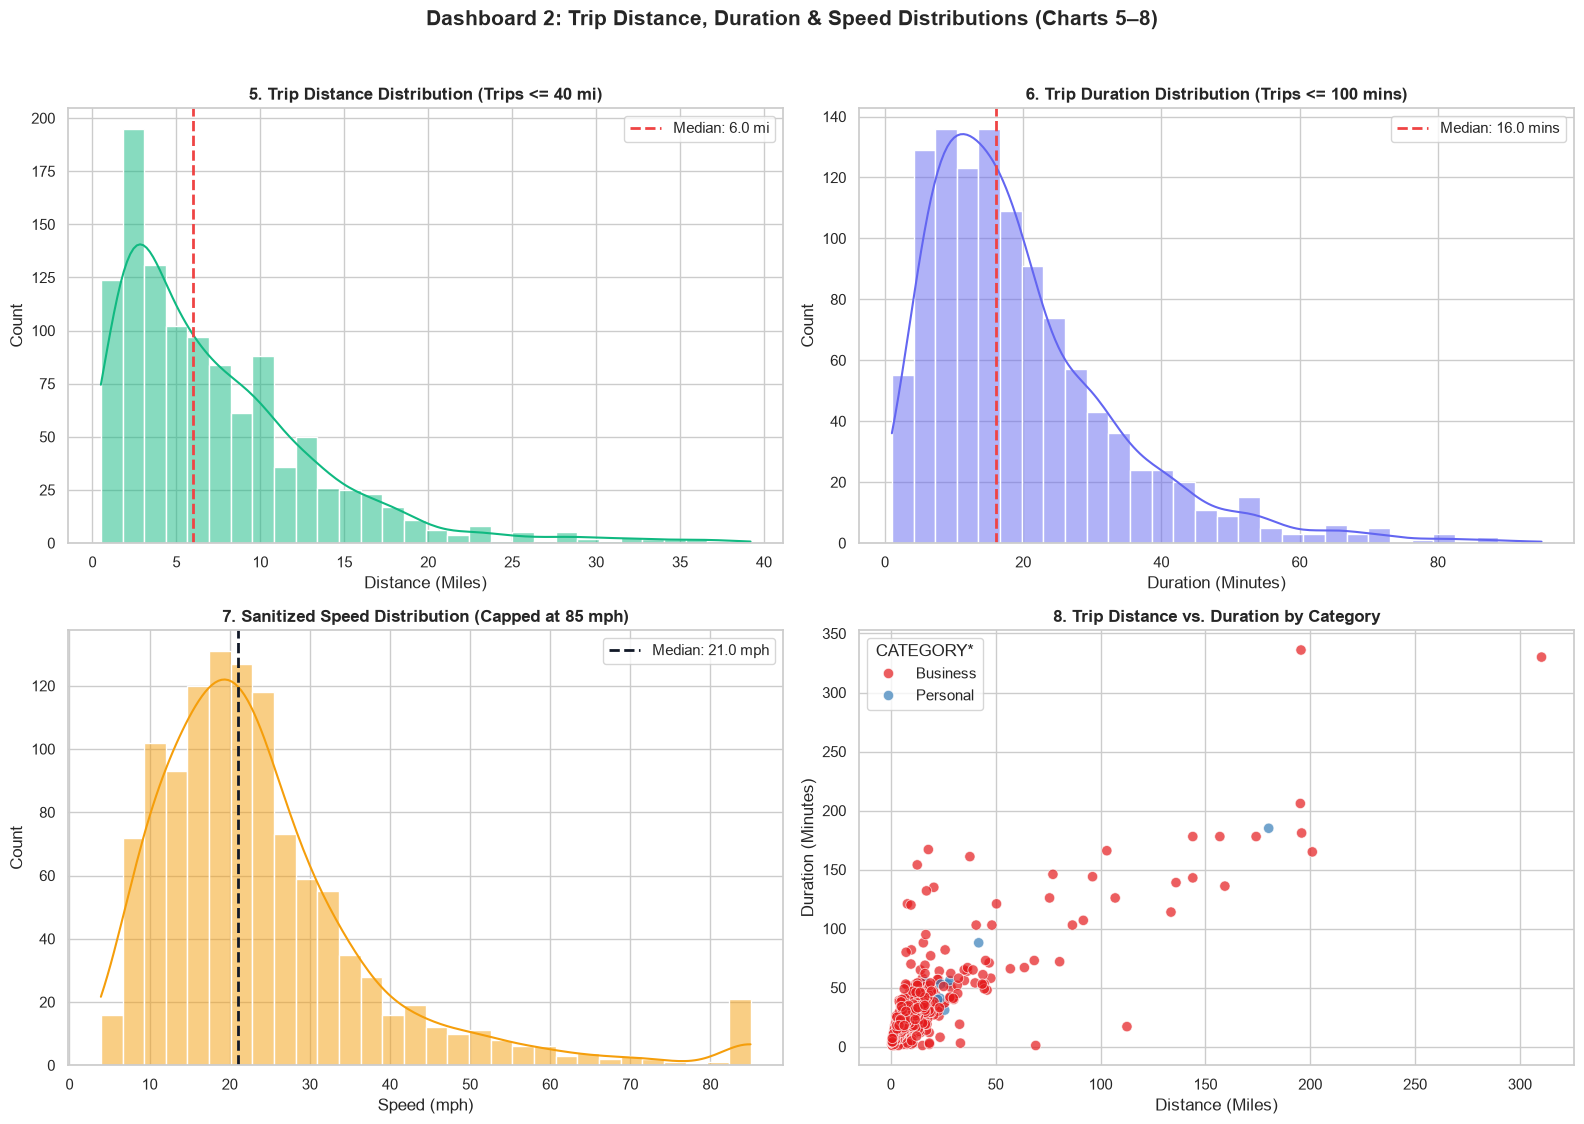

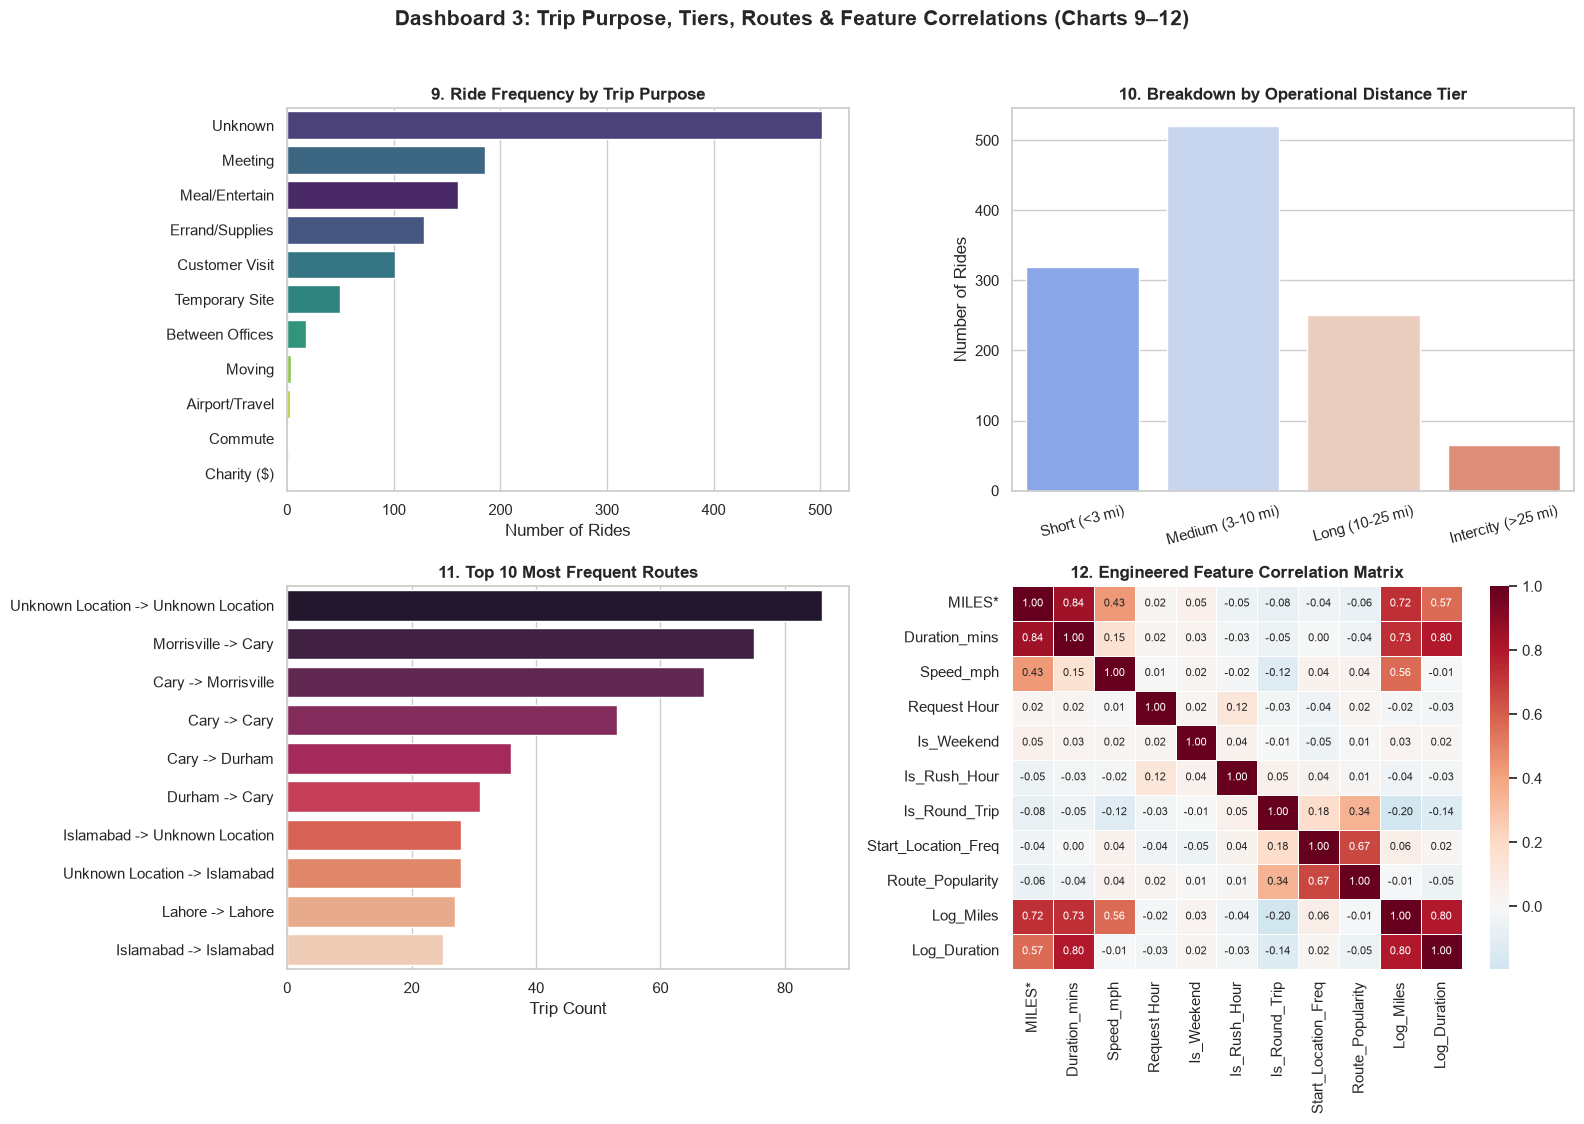


STEP 3 COMPLETED SUCCESSFULLY: ALL 12 CHARTS GENERATED


In [4]:
print("=" * 60)
print("STARTING STEP 3: EXPLORATORY DATA ANALYSIS (12 CHARTS TOTAL)")
print("=" * 60)

sns.set_theme(style="whitegrid", context="notebook", palette="viridis")

# ==============================================================================
# DASHBOARD 1: TEMPORAL & HOURLY DEMAND PATTERNS (CHARTS 1 - 4)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Dashboard 1: Temporal & Hourly Ride Demand Patterns (Charts 1–4)", fontsize=15, fontweight="bold", y=1.02)

# Chart 1: Hourly Ride Volume + 3-Hour Rolling Average
axes[0, 0].bar(hourly_df["Request Hour"], hourly_df["Total_Rides"], color="#3b82f6", alpha=0.75, label="Hourly Rides")
axes[0, 0].plot(hourly_df["Request Hour"], hourly_df["Rolling_3hr_Avg_Rides"], color="#ef4444", marker="o", linewidth=2.2, label="3-Hr Rolling Avg")
axes[0, 0].set_title("1. Hourly Ride Demand & 3-Hr Rolling Trend", fontweight="bold")
axes[0, 0].set_xlabel("Hour of Day (0–23)")
axes[0, 0].set_ylabel("Number of Rides")
axes[0, 0].set_xticks(range(0, 24, 2))
axes[0, 0].legend()

# Chart 2: Rides by Day of Week (Ordered Mon -> Sun)
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.countplot(data=df, x="Request Day", order=day_order, ax=axes[0, 1], palette="crest", hue="Request Day", legend=False)
axes[0, 1].set_title("2. Total Rides by Day of Week", fontweight="bold")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Ride Count")
axes[0, 1].tick_params(axis="x", rotation=25)

# Chart 3: Monthly Ride Seasonality (Ordered Jan -> Dec)
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
sns.countplot(data=df, x="Request Month", order=month_order, ax=axes[1, 0], palette="mako", hue="Request Month", legend=False)
axes[1, 0].set_title("3. Monthly Ride Volume Seasonality", fontweight="bold")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Ride Count")
axes[1, 0].tick_params(axis="x", rotation=35)

# Chart 4: Hour x Day-of-Week Demand Heatmap
heatmap_data = df.pivot_table(index="Request Day", columns="Request Hour", values="MILES*", aggfunc="count").reindex(day_order).fillna(0)
sns.heatmap(heatmap_data, cmap="YlGnBu", linewidths=0.4, ax=axes[1, 1], cbar_kws={"label": "Rides"})
axes[1, 1].set_title("4. Ride Density Heatmap (Day vs. Hour)", fontweight="bold")
axes[1, 1].set_xlabel("Hour of Day")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

# ==============================================================================
# DASHBOARD 2: TRIP DISTRIBUTIONS & SANITIZED PHYSICS (CHARTS 5 - 8)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Dashboard 2: Trip Distance, Duration & Speed Distributions (Charts 5–8)", fontsize=15, fontweight="bold", y=1.02)

# Chart 5: Trip Distance Distribution (Zoomed <= 40 miles + Median marker)
sns.histplot(df[df["MILES*"] <= 40]["MILES*"], bins=30, kde=True, color="#10b981", ax=axes[0, 0]) # type: ignore
axes[0, 0].axvline(df["MILES*"].median(), color="#ef4444", linestyle="--", linewidth=2, label=f"Median: {df['MILES*'].median():.1f} mi")
axes[0, 0].set_title("5. Trip Distance Distribution (Trips <= 40 mi)", fontweight="bold")
axes[0, 0].set_xlabel("Distance (Miles)")
axes[0, 0].legend()

# Chart 6: Sanitized Trip Duration Distribution (<= 100 mins)
sns.histplot(df[df["Duration_mins"] <= 100]["Duration_mins"], bins=30, kde=True, color="#6366f1", ax=axes[0, 1]) # type: ignore
axes[0, 1].axvline(df["Duration_mins"].median(), color="#ef4444", linestyle="--", linewidth=2, label=f"Median: {df['Duration_mins'].median():.1f} mins")
axes[0, 1].set_title("6. Trip Duration Distribution (Trips <= 100 mins)", fontweight="bold")
axes[0, 1].set_xlabel("Duration (Minutes)")
axes[0, 1].legend()

# Chart 7: Sanitized Speed Distribution (Capped at 85 mph)
sns.histplot(
    data=df[df["Speed_mph"] <= 85],
    x="Speed_mph",
    bins=30,
    kde=True,
    color="#f59e0b",
    ax=axes[1, 0]
)
axes[1, 0].axvline(df["Speed_mph"].median(), color="#111827", linestyle="--", linewidth=2, label=f"Median: {df['Speed_mph'].median():.1f} mph")
axes[1, 0].set_title("7. Sanitized Speed Distribution (Capped at 85 mph)", fontweight="bold")
axes[1, 0].set_xlabel("Speed (mph)")
axes[1, 0].legend()

# Chart 8: Distance vs. Duration Scatter by Category
sns.scatterplot(data=df, x="MILES*", y="Duration_mins", hue="CATEGORY*", alpha=0.7, s=55, palette="Set1", ax=axes[1, 1])
axes[1, 1].set_title("8. Trip Distance vs. Duration by Category", fontweight="bold")
axes[1, 1].set_xlabel("Distance (Miles)")
axes[1, 1].set_ylabel("Duration (Minutes)")

plt.tight_layout()
plt.show()

# ==============================================================================
# DASHBOARD 3: OPERATIONAL SEGMENTS, ROUTES & CORRELATIONS (CHARTS 9 - 12)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Dashboard 3: Trip Purpose, Tiers, Routes & Feature Correlations (Charts 9–12)", fontsize=15, fontweight="bold", y=1.02)

# Chart 9: Trip Counts by Purpose
purpose_order = df["PURPOSE*"].value_counts().index
sns.countplot(data=df, y="PURPOSE*", order=purpose_order, ax=axes[0, 0], palette="viridis", hue="PURPOSE*", legend=False)
axes[0, 0].set_title("9. Ride Frequency by Trip Purpose", fontweight="bold")
axes[0, 0].set_xlabel("Number of Rides")
axes[0, 0].set_ylabel("")

# Chart 10: Operational Distance Tiers
tier_order = ["Short (<3 mi)", "Medium (3-10 mi)", "Long (10-25 mi)", "Intercity (>25 mi)"]
sns.countplot(data=df, x="Distance_Tier", order=tier_order, ax=axes[0, 1], palette="coolwarm", hue="Distance_Tier", legend=False)
axes[0, 1].set_title("10. Breakdown by Operational Distance Tier", fontweight="bold")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Number of Rides")
axes[0, 1].tick_params(axis="x", rotation=15)

# Chart 11: Top 10 Most Frequent Routes
top_routes = df["Route"].value_counts().head(10)
sns.barplot(x=top_routes.values, y=top_routes.index, ax=axes[1, 0], palette="rocket", hue=top_routes.index, legend=False)
axes[1, 0].set_title("11. Top 10 Most Frequent Routes", fontweight="bold")
axes[1, 0].set_xlabel("Trip Count")
axes[1, 0].set_ylabel("")

# Chart 12: Core Feature Correlation Matrix
corr_cols = [
    "MILES*", "Duration_mins", "Speed_mph", "Request Hour",
    "Is_Weekend", "Is_Rush_Hour", "Is_Round_Trip",
    "Start_Location_Freq", "Route_Popularity", "Log_Miles", "Log_Duration"
]
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5, ax=axes[1, 1], annot_kws={"size": 8})
axes[1, 1].set_title("12. Engineered Feature Correlation Matrix", fontweight="bold")

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("STEP 3 COMPLETED SUCCESSFULLY: ALL 12 CHARTS GENERATED")
print("=" * 60)

STARTING STEP 4: LOG-TRANSFORMED MACHINE LEARNING MODEL BENCHMARKING

[1] Leak-Free Dataset Ready -> 1154 samples | 44 encoded features
    -> Train Split: 923 rows | Test Split: 231 rows

--- 2. MODEL PERFORMANCE EVALUATION LEADERBOARD ---


,Model,RMSE (Mins),MAE (Mins),R2 Score,R2 Score (%)
0,XGBoost (Tuned for Small N) [Log-Target],5.5272,2.2104,0.9559,95.59%
1,Random Forest (Regularized) [Log-Target],6.1270,2.2909,0.9458,94.58%
2,Gradient Boosting (Tuned) [Log-Target],6.8897,2.1176,0.9314,93.14%
3,Linear Regression [Log-Target],7.5786,5.1826,0.9170,91.70%
4,Extra Trees (Regularized) [Log-Target],8.5590,3.4390,0.8942,89.42%



--- 3. PREDICTION INFERENCE (HIGH-DURATION TRIP DETECTION) ---


,Best Performing Model,Duration Threshold (Train Mean),Total Test Trips,Accuracy,Precision,Recall (Long Trips Caught),F1-Score,True Positives,True Negatives,False Positives,False Negatives (Missed)
0,XGBoost (Tuned for Small N) [Log-Target],>= 23.27 mins,231,95.67% (221/231),92.86%,92.86%,92.86%,65,156,5,5


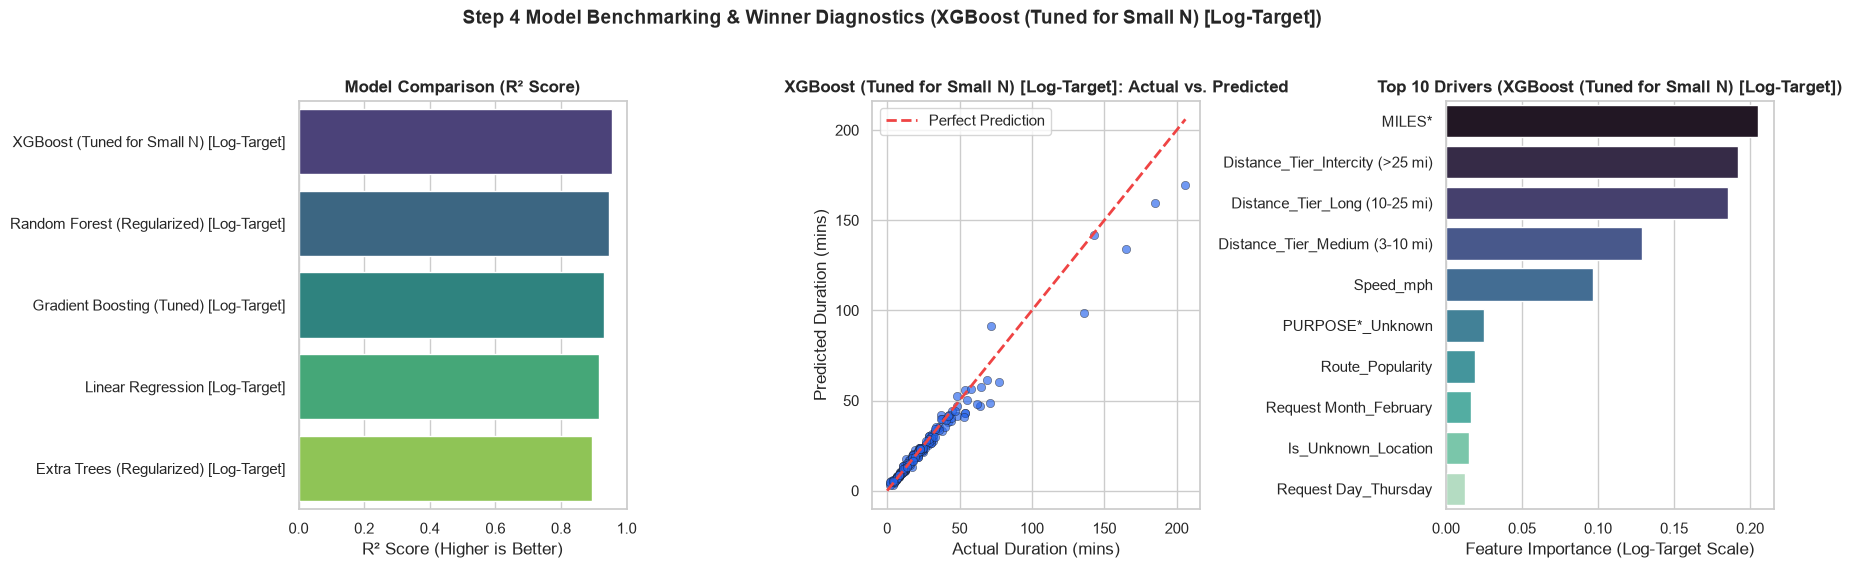

STEP 4 COMPLETED SUCCESSFULLY
 -> Winner: XGBoost (Tuned for Small N) [Log-Target] | RMSE = 5.5272 mins | R² = 0.9559 (95.59%) | MAE = 2.2104 mins | F1 = 92.86%


In [5]:
print("=" * 72)
print("STARTING STEP 4: LOG-TRANSFORMED MACHINE LEARNING MODEL BENCHMARKING")
print("=" * 72)

# Prepare a random train/test split for trip-duration regression
reg_feature_cols = [
    "MILES*", "Speed_mph", "Request Hour", "Request Day", "Request Month",
    "Is_Weekend", "Hour_Sin", "Hour_Cos", "Day_Of_Week", "Is_Rush_Hour",
    "Is_Round_Trip", "Is_Unknown_Location", "Distance_Tier",
    "Start_Location_Freq", "Stop_Location_Freq", "Route_Popularity",
    "CATEGORY*", "PURPOSE*",
]
X_reg = pd.get_dummies(
    df[reg_feature_cols],
    columns=["Request Day", "Request Month", "Distance_Tier", "CATEGORY*", "PURPOSE*"],
    drop_first=True,
)
y_reg = df["Duration_mins"]
X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

print(f"\n[1] Leak-Free Dataset Ready -> {len(X_train) + len(X_test)} samples | {X_train.shape[1]} encoded features")
print(f"    -> Train Split: {len(X_train)} rows | Test Split: {len(X_test)} rows")

# -------------------------------------------------------------------------
# 1. DEFINE MODELS WITH LOG1P TARGET TRANSFORMATION & BALANCED REGULARIZATION
# -------------------------------------------------------------------------
base_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest (Regularized)": RandomForestRegressor(
        n_estimators=200, max_depth=8, min_samples_leaf=4, random_state=42, n_jobs=-1
    ),
    "Extra Trees (Regularized)": ExtraTreesRegressor(
        n_estimators=200, max_depth=8, min_samples_leaf=4, random_state=42, n_jobs=-1
    ),
    "XGBoost (Tuned for Small N)": XGBRegressor(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.5,
        reg_lambda=1.5,
        random_state=42,
        n_jobs=-1,
    ),
    "Gradient Boosting (Tuned)": GradientBoostingRegressor(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        min_samples_leaf=4,
        subsample=0.8,
        random_state=42,
    ),
}

models = {
    f"{name} [Log-Target]": TransformedTargetRegressor(
        regressor=est, func=np.log1p, inverse_func=np.expm1
    )
    for name, est in base_models.items()
}

# -------------------------------------------------------------------------
# 2. TRAIN & BENCHMARK ALL MODELS IN ORIGINAL MINUTE SCALE
# -------------------------------------------------------------------------
results = []
trained_models = {}
predictions_store = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = np.clip(model.predict(X_test), a_min=0, a_max=None)

    rmse = root_mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results.append({
        "Model": name,
        "RMSE (Mins)": round(rmse, 4),
        "MAE (Mins)": round(mae, 4),
        "R2 Score": round(r2, 4),
        "R2 Score (%)": f"{r2 * 100:.2f}%",
    })
    trained_models[name] = model
    predictions_store[name] = preds

comparison_df = (
    pd.DataFrame(results)
    .sort_values(by=["RMSE (Mins)", "R2 Score"], ascending=[True, False])
    .reset_index(drop=True)
)

print("\n--- 2. MODEL PERFORMANCE EVALUATION LEADERBOARD ---")
display(comparison_df)

best_model_name = comparison_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
final_preds = predictions_store[best_model_name]

# -------------------------------------------------------------------------
# 3. PREDICTION INFERENCE (HIGH-DURATION TRIP DETECTION)
# -------------------------------------------------------------------------
threshold = round(float(y_train.mean()), 2)
actual_long = y_test >= threshold
pred_long = final_preds >= threshold

total_test_samples = len(y_test)
correct_pred = int((actual_long == pred_long).sum())
tp = int((actual_long & pred_long).sum())
tn = int((~actual_long & ~pred_long).sum())
fp = int((~actual_long & pred_long).sum())
fn = int((actual_long & ~pred_long).sum())

prec = precision_score(actual_long, pred_long, zero_division=0)
rec = recall_score(actual_long, pred_long, zero_division=0)
f1 = f1_score(actual_long, pred_long, zero_division=0)

inference_summary = pd.DataFrame([{
    "Best Performing Model": best_model_name,
    "Duration Threshold (Train Mean)": f">= {threshold} mins",
    "Total Test Trips": total_test_samples,
    "Accuracy": f"{(correct_pred / total_test_samples) * 100:.2f}% ({correct_pred}/{total_test_samples})",
    "Precision": f"{prec * 100:.2f}%",
    "Recall (Long Trips Caught)": f"{rec * 100:.2f}%",
    "F1-Score": f"{f1 * 100:.2f}%",
    "True Positives": tp,
    "True Negatives": tn,
    "False Positives": fp,
    "False Negatives (Missed)": fn,
}])

print("\n--- 3. PREDICTION INFERENCE (HIGH-DURATION TRIP DETECTION) ---")
display(inference_summary)

# -------------------------------------------------------------------------
# 4. VISUAL DIAGNOSTICS
# -------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle(
    f"Step 4 Model Benchmarking & Winner Diagnostics ({best_model_name})",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)

sns.barplot(
    data=comparison_df,
    x="R2 Score",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Model Comparison (R² Score)", fontweight="bold")
axes[0].set_xlabel("R² Score (Higher is Better)")
axes[0].set_ylabel("")
axes[0].set_xlim(min(0, comparison_df["R2 Score"].min() - 0.05), 1.0)

axes[1].scatter(y_test, final_preds, alpha=0.65, color="#2563eb", edgecolors="k", linewidth=0.4)
max_val = max(y_test.max(), final_preds.max())
axes[1].plot([0, max_val], [0, max_val], color="#ef4444", linestyle="--", linewidth=2, label="Perfect Prediction")
axes[1].set_title(f"{best_model_name}: Actual vs. Predicted", fontweight="bold")
axes[1].set_xlabel("Actual Duration (mins)")
axes[1].set_ylabel("Predicted Duration (mins)")
axes[1].legend()

inner_reg = best_model.regressor_ if hasattr(best_model, "regressor_") else best_model
estimator = inner_reg.steps[-1][1] if hasattr(inner_reg, "steps") else inner_reg

if hasattr(estimator, "feature_importances_"):
    imp = pd.Series(estimator.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
    xlabel = "Feature Importance (Log-Target Scale)"
elif hasattr(estimator, "coef_"):
    imp = pd.Series(np.abs(estimator.coef_), index=X_train.columns).sort_values(ascending=False).head(10)
    xlabel = "|Standardized Coefficient| (Log-Target Scale)"
else:
    perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42)
    imp = pd.Series(perm.importances_mean, index=X_train.columns).sort_values(ascending=False).head(10) # type: ignore
    xlabel = "Permutation Importance (Mins)"

sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette="mako", legend=False, ax=axes[2])
axes[2].set_title(f"Top 10 Drivers ({best_model_name})", fontweight="bold")
axes[2].set_xlabel(xlabel)
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

print("=" * 72)
print("STEP 4 COMPLETED SUCCESSFULLY")
print(
    f" -> Winner: {best_model_name} | RMSE = {comparison_df.iloc[0]['RMSE (Mins)']} mins | "
    f"R² = {comparison_df.iloc[0]['R2 Score']} ({comparison_df.iloc[0]['R2 Score (%)']}) | "
    f"MAE = {comparison_df.iloc[0]['MAE (Mins)']} mins | F1 = {f1 * 100:.2f}%"
)
print("=" * 72)

STARTING STEP 5: 4-HOUR BLOCK SURGE CLASSIFICATION (PR-AUC & CLASS-BALANCED)

[1] 4-Hour Block Grid Ready -> 2,196 blocks (2016-01-01 to 2016-12-31)
    -> Zero-Ride Sparsity reduced to 69.6% | Surge Definition: >= 2 rides / 4-hr block
    -> Train: 1,756 blocks (Surge rate: 12.2%) | Test: 440 blocks (Surge rate: 18.9%)

--- 2. SURGE CLASSIFICATION LEADERBOARD (RANKED BY PR-AUC) ---


,Model,PR-AUC (Primary),ROC-AUC,Balanced Acc,Surge F1,Precision,Recall
0,Logistic Regression (Balanced),0.4174,0.8057,67.82%,46.56%,41.51%,53.01%
1,Extra Trees (Balanced),0.4070,0.7853,69.24%,47.22%,38.35%,61.45%
2,Random Forest (Balanced),0.3933,0.7846,64.91%,42.70%,40.00%,45.78%
3,Gradient Boosting (Regularized),0.3503,0.7601,61.95%,38.27%,39.24%,37.35%
4,XGBoost (Scale-Pos-Weighted),0.3332,0.7477,58.18%,32.37%,31.11%,33.73%



--- 3. PREDICTION INFERENCE (4-HOUR SURGE ALERT PERFORMANCE) ---


,Best Performing Model,Surge Definition (Train),Tuned Prob Cutoff (Val F1),PR-AUC (vs Baseline),Balanced Accuracy,Precision,Recall (Surges Caught),F1-Score,TP / FP / FN / TN
0,Logistic Regression (Balanced),>= 2 rides / 4h,>= 0.667,0.4174 (vs 0.1886),67.82%,41.51%,53.01%,46.56%,44 / 62 / 39 / 295


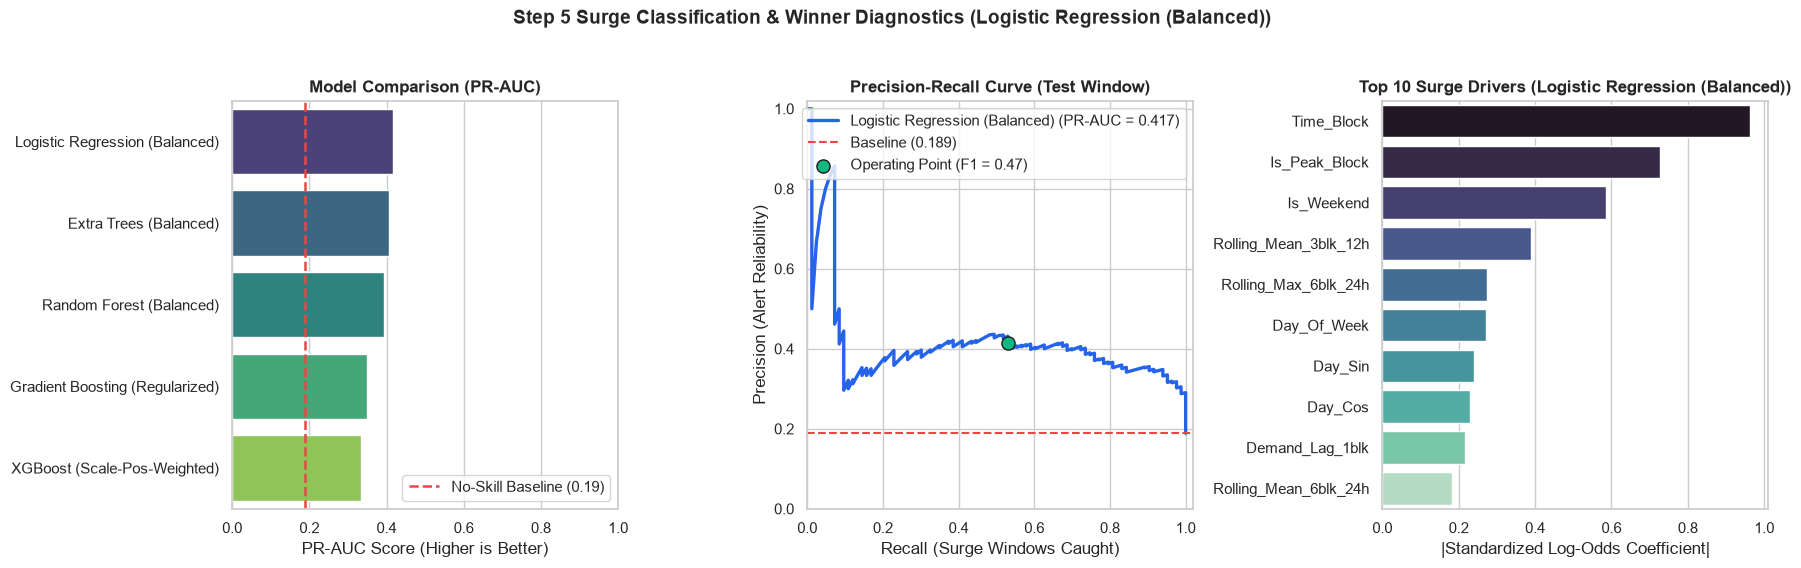


PIPELINE COMPLETE (STEPS 1–5 EXECUTED SUCCESSFULLY)
 -> Winner: Logistic Regression (Balanced) | PR-AUC = 0.4174 (Baseline: 0.1886) | Balanced Acc = 67.82% | Surge F1 = 46.56%


In [6]:

print("=" * 76)
print("STARTING STEP 5: 4-HOUR BLOCK SURGE CLASSIFICATION (PR-AUC & CLASS-BALANCED)")
print("=" * 76)

# -------------------------------------------------------------------------
# 1. AGGREGATE INTO DENSE 4-HOUR TIME BLOCKS (REDUCES SPARSITY)
# -------------------------------------------------------------------------
df["Request_Date"] = df["START_DATE*"].dt.floor("D")
df["Time_Block"] = df["Request Hour"] // 4  # 0..5 (6 blocks per day)

block_labels = {
    0: "00:00-04:00 (Late Night)",
    1: "04:00-08:00 (Early Morning)",
    2: "08:00-12:00 (Morning Rush)",
    3: "12:00-16:00 (Afternoon)",
    4: "16:00-20:00 (Evening Rush)",
    5: "20:00-24:00 (Night)",
}

min_date = df["Request_Date"].min()
max_date = df["Request_Date"].max()
all_dates = pd.date_range(start=min_date, end=max_date, freq="D")
all_blocks = range(6)

full_grid = (
    pd.MultiIndex.from_product([all_dates, all_blocks], names=["Request_Date", "Time_Block"])
    .to_frame()
    .reset_index(drop=True)
)

block_counts = (
    df.groupby(["Request_Date", "Time_Block"])
    .size()
    .reset_index(name="Ride_Count")
)

ts_df = pd.merge(full_grid, block_counts, on=["Request_Date", "Time_Block"], how="left")
ts_df["Ride_Count"] = ts_df["Ride_Count"].fillna(0)
ts_df = ts_df.sort_values(by=["Request_Date", "Time_Block"]).reset_index(drop=True)
ts_df["Timestamp"] = ts_df["Request_Date"] + pd.to_timedelta(ts_df["Time_Block"] * 4, unit="h")

# Calendar & Cyclical Encodings
ts_df["Day_Of_Week"] = ts_df["Request_Date"].dt.dayofweek
ts_df["Month"] = ts_df["Request_Date"].dt.month
ts_df["Is_Weekend"] = (ts_df["Day_Of_Week"] >= 5).astype(int)
ts_df["Is_Peak_Block"] = ts_df["Time_Block"].isin([2, 3, 4]).astype(int)  # 08:00 - 20:00

ts_df["Block_Sin"] = np.sin(2 * np.pi * ts_df["Time_Block"] / 6.0)
ts_df["Block_Cos"] = np.cos(2 * np.pi * ts_df["Time_Block"] / 6.0)
ts_df["Day_Sin"] = np.sin(2 * np.pi * ts_df["Day_Of_Week"] / 7.0)
ts_df["Day_Cos"] = np.cos(2 * np.pi * ts_df["Day_Of_Week"] / 7.0)

# Strictly Shifted Lags & Rolling Momentum Features (Zero Target Leakage)
# 1 block = 4h | 6 blocks = 24h (1 day) | 42 blocks = 168h (same block last week)
ts_df["Demand_Lag_1blk"] = ts_df["Ride_Count"].shift(1).fillna(0)
ts_df["Demand_Lag_2blk"] = ts_df["Ride_Count"].shift(2).fillna(0)
ts_df["Demand_Lag_6blk_24h"] = ts_df["Ride_Count"].shift(6).fillna(0)
ts_df["Demand_Lag_42blk_7d"] = ts_df["Ride_Count"].shift(42).fillna(0)

ts_df["Rolling_Mean_3blk_12h"] = (
    ts_df["Ride_Count"].shift(1).rolling(window=3, min_periods=1).mean().fillna(0)
)
ts_df["Rolling_Mean_6blk_24h"] = (
    ts_df["Ride_Count"].shift(1).rolling(window=6, min_periods=1).mean().fillna(0)
)
ts_df["Rolling_Max_6blk_24h"] = (
    ts_df["Ride_Count"].shift(1).rolling(window=6, min_periods=1).max().fillna(0)
)

ts_features = [
    "Time_Block",
    "Day_Of_Week",
    "Month",
    "Is_Weekend",
    "Is_Peak_Block",
    "Block_Sin",
    "Block_Cos",
    "Day_Sin",
    "Day_Cos",
    "Demand_Lag_1blk",
    "Demand_Lag_2blk",
    "Demand_Lag_6blk_24h",
    "Demand_Lag_42blk_7d",
    "Rolling_Mean_3blk_12h",
    "Rolling_Mean_6blk_24h",
    "Rolling_Max_6blk_24h",
]

# -------------------------------------------------------------------------
# 2. CHRONOLOGICAL SPLIT & LEAK-FREE SURGE TARGET DEFINITION
# -------------------------------------------------------------------------
split_idx = int(len(ts_df) * 0.80)
train_df = ts_df.iloc[:split_idx].copy()
test_df = ts_df.iloc[split_idx:].copy()

# Define Surge strictly from Training Set (e.g., >= 2 rides in a 4-hr block, or train 75th percentile)
surge_cutoff_rides = max(2, int(np.ceil(train_df["Ride_Count"].quantile(0.75))))

y_train_clf = (train_df["Ride_Count"] >= surge_cutoff_rides).astype(int)
y_test_clf = (test_df["Ride_Count"] >= surge_cutoff_rides).astype(int)

X_train_clf = train_df[ts_features]
X_test_clf = test_df[ts_features]
test_timestamps = test_df["Timestamp"]

# Compute imbalance ratio strictly from training labels for XGBoost
neg_count = int((y_train_clf == 0).sum())
pos_count = max(1, int((y_train_clf == 1).sum()))
scale_pos_weight = round(neg_count / pos_count, 2)

zero_pct = (ts_df["Ride_Count"] == 0).mean() * 100
print(f"\n[1] 4-Hour Block Grid Ready -> {len(ts_df):,} blocks ({min_date.date()} to {max_date.date()})")
print(f"    -> Zero-Ride Sparsity reduced to {zero_pct:.1f}% | Surge Definition: >= {surge_cutoff_rides} rides / 4-hr block")
print(f"    -> Train: {len(X_train_clf):,} blocks (Surge rate: {y_train_clf.mean()*100:.1f}%) | "
      f"Test: {len(X_test_clf):,} blocks (Surge rate: {y_test_clf.mean()*100:.1f}%)")

# -------------------------------------------------------------------------
# 3. DEFINE CLASS-BALANCED SURGE CLASSIFIERS
# -------------------------------------------------------------------------
clf_models = {
    "Logistic Regression (Balanced)": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", C=1.0, max_iter=500, random_state=42),
    ),
    "Random Forest (Balanced)": RandomForestClassifier(
        n_estimators=250,
        max_depth=6,
        min_samples_leaf=6,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "Extra Trees (Balanced)": ExtraTreesClassifier(
        n_estimators=250,
        max_depth=6,
        min_samples_leaf=6,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "XGBoost (Scale-Pos-Weighted)": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
    ),
    "Gradient Boosting (Regularized)": GradientBoostingClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.04,
        min_samples_leaf=6,
        subsample=0.8,
        random_state=42,
    ),
}

# Chronological internal validation split (last 20% of train) for leak-free threshold tuning
val_split = int(len(X_train_clf) * 0.80)
X_tr_sub, X_val_sub = X_train_clf.iloc[:val_split], X_train_clf.iloc[val_split:]
y_tr_sub, y_val_sub = y_train_clf.iloc[:val_split], y_train_clf.iloc[val_split:]

results = []
trained_clfs = {}
test_probs_store = {}
best_thresholds = {}

for name, clf in clf_models.items():
    # Step A: Tune probability threshold on internal validation slice to maximize F1
    clf.fit(X_tr_sub, y_tr_sub)
    val_probs = clf.predict_proba(X_val_sub)[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y_val_sub, val_probs)
    f1_scores = (2 * precisions[:-1] * recalls[:-1]) / np.maximum(
        precisions[:-1] + recalls[:-1], 1e-8
    )
    opt_thresh = float(thresholds[np.argmax(f1_scores)]) if len(thresholds) > 0 else 0.50

    # Step B: Refit on full training window and evaluate on held-out test window
    clf.fit(X_train_clf, y_train_clf)
    test_probs = clf.predict_proba(X_test_clf)[:, 1]
    test_preds = (test_probs >= opt_thresh).astype(int)

    pr_auc = average_precision_score(y_test_clf, test_probs)
    roc_auc = roc_auc_score(y_test_clf, test_probs)
    bal_acc = balanced_accuracy_score(y_test_clf, test_preds)
    f1 = f1_score(y_test_clf, test_preds, zero_division=0)
    prec = precision_score(y_test_clf, test_preds, zero_division=0)
    rec = recall_score(y_test_clf, test_preds, zero_division=0)

    results.append({
        "Model": name,
        "PR-AUC (Primary)": round(pr_auc, 4),
        "ROC-AUC": round(roc_auc, 4),
        "Balanced Acc": f"{bal_acc * 100:.2f}%",
        "Surge F1": f"{f1 * 100:.2f}%",
        "Precision": f"{prec * 100:.2f}%",
        "Recall": f"{rec * 100:.2f}%",
    })
    trained_clfs[name] = clf
    test_probs_store[name] = test_probs
    best_thresholds[name] = opt_thresh

leaderboard_df = (
    pd.DataFrame(results)
    .sort_values(by=["PR-AUC (Primary)", "ROC-AUC"], ascending=[False, False])
    .reset_index(drop=True)
)

print("\n--- 2. SURGE CLASSIFICATION LEADERBOARD (RANKED BY PR-AUC) ---")
display(leaderboard_df)

# Select winner based on PR-AUC
best_clf_name = leaderboard_df.iloc[0]["Model"]
best_clf = trained_clfs[best_clf_name]
best_probs = test_probs_store[best_clf_name]
best_cutoff = best_thresholds[best_clf_name]
final_surge_preds = (best_probs >= best_cutoff).astype(int)

# -------------------------------------------------------------------------
# 4. DETAILED INFERENCE SUMMARY (NO MISLEADING RAW ACCURACY)
# -------------------------------------------------------------------------
tn, fp, fn, tp = confusion_matrix(y_test_clf, final_surge_preds).ravel()
pr_auc_win = average_precision_score(y_test_clf, best_probs)
bal_acc_win = balanced_accuracy_score(y_test_clf, final_surge_preds)
prec_win = precision_score(y_test_clf, final_surge_preds, zero_division=0)
rec_win = recall_score(y_test_clf, final_surge_preds, zero_division=0)
f1_win = f1_score(y_test_clf, final_surge_preds, zero_division=0)
baseline_pr_auc = y_test_clf.mean()  # Random baseline PR-AUC equals positive class prevalence

inference_summary = pd.DataFrame([{
    "Best Performing Model": best_clf_name,
    "Surge Definition (Train)": f">= {surge_cutoff_rides} rides / 4h",
    "Tuned Prob Cutoff (Val F1)": f">= {best_cutoff:.3f}",
    "PR-AUC (vs Baseline)": f"{pr_auc_win:.4f} (vs {baseline_pr_auc:.4f})",
    "Balanced Accuracy": f"{bal_acc_win * 100:.2f}%",
    "Precision": f"{prec_win * 100:.2f}%",
    "Recall (Surges Caught)": f"{rec_win * 100:.2f}%",
    "F1-Score": f"{f1_win * 100:.2f}%",
    "TP / FP / FN / TN": f"{tp} / {fp} / {fn} / {tn}",
}])

print("\n--- 3. PREDICTION INFERENCE (4-HOUR SURGE ALERT PERFORMANCE) ---")
display(inference_summary)

# -------------------------------------------------------------------------
# 5. VISUAL DIAGNOSTICS: PR-AUC LEADERBOARD, PR CURVE & TOP DRIVERS
# -------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle(
    f"Step 5 Surge Classification & Winner Diagnostics ({best_clf_name})",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)

# Panel 1: PR-AUC Leaderboard
sns.barplot(
    data=leaderboard_df,
    x="PR-AUC (Primary)",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False,
    ax=axes[0],
)
axes[0].axvline(
    baseline_pr_auc, color="#ef4444", linestyle="--", linewidth=1.8, label=f"No-Skill Baseline ({baseline_pr_auc:.2f})"
)
axes[0].set_title("Model Comparison (PR-AUC)", fontweight="bold")
axes[0].set_xlabel("PR-AUC Score (Higher is Better)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 1.0)
axes[0].legend(loc="lower right")

# Panel 2: Precision-Recall Curve for Winner
prec_curve, rec_curve, _ = precision_recall_curve(y_test_clf, best_probs)
axes[1].plot(rec_curve, prec_curve, color="#2563eb", linewidth=2.4, label=f"{best_clf_name} (PR-AUC = {pr_auc_win:.3f})")
axes[1].axhline(baseline_pr_auc, color="#ef4444", linestyle="--", linewidth=1.5, label=f"Baseline ({baseline_pr_auc:.3f})")
axes[1].scatter([rec_win], [prec_win], color="#10b981", s=90, zorder=5, edgecolor="k", label=f"Operating Point (F1 = {f1_win:.2f})")
axes[1].set_title("Precision-Recall Curve (Test Window)", fontweight="bold")
axes[1].set_xlabel("Recall (Surge Windows Caught)")
axes[1].set_ylabel("Precision (Alert Reliability)")
axes[1].set_xlim(0, 1.02)
axes[1].set_ylim(0, 1.02)
axes[1].legend(loc="upper right")

# Panel 3: Top 10 Feature Drivers
estimator = best_clf.steps[-1][1] if hasattr(best_clf, "steps") else best_clf
if hasattr(estimator, "feature_importances_"):
    imp = (
        pd.Series(estimator.feature_importances_, index=ts_features)
        .sort_values(ascending=False)
        .head(10)
    )
    xlabel = "Feature Importance (Gini / Gain)"
else:
    imp = (
        pd.Series(np.abs(estimator.coef_[0]), index=ts_features)
        .sort_values(ascending=False)
        .head(10)
    )
    xlabel = "|Standardized Log-Odds Coefficient|"

sns.barplot(
    x=imp.values,
    y=imp.index,
    hue=imp.index,
    palette="mako",
    legend=False,
    ax=axes[2],
)
axes[2].set_title(f"Top 10 Surge Drivers ({best_clf_name})", fontweight="bold")
axes[2].set_xlabel(xlabel)
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

print("\n" + "=" * 76)
print("PIPELINE COMPLETE (STEPS 1–5 EXECUTED SUCCESSFULLY)")
print(
    f" -> Winner: {best_clf_name} | PR-AUC = {pr_auc_win:.4f} (Baseline: {baseline_pr_auc:.4f}) | "
    f"Balanced Acc = {bal_acc_win * 100:.2f}% | Surge F1 = {f1_win * 100:.2f}%"
)
print("=" * 76)

STEP FINAL: TIME-SERIES DEMAND FORECASTING & SURGE CLASSIFICATION


,Pipeline Architecture,Grid Resolution,Zero-Slot Sparsity,Selected Model,PR-AUC (vs Baseline),Balanced Accuracy,Precision,Recall,Surge F1-Score
0,1. Hourly Demand Regression (Baseline),"8,784 hrs (1-hr)",88.5%,Random Forest Regressor,0.3434 (vs 0.1537),66.51%,31.81%,54.07%,40.05%
1,2. 4-Hour Block Surge Classifier (Final),"2,196 blocks (4-hr)",69.6%,Logistic Regression (Balanced),0.4174 (vs 0.1886),67.82%,41.51%,53.01%,46.56%


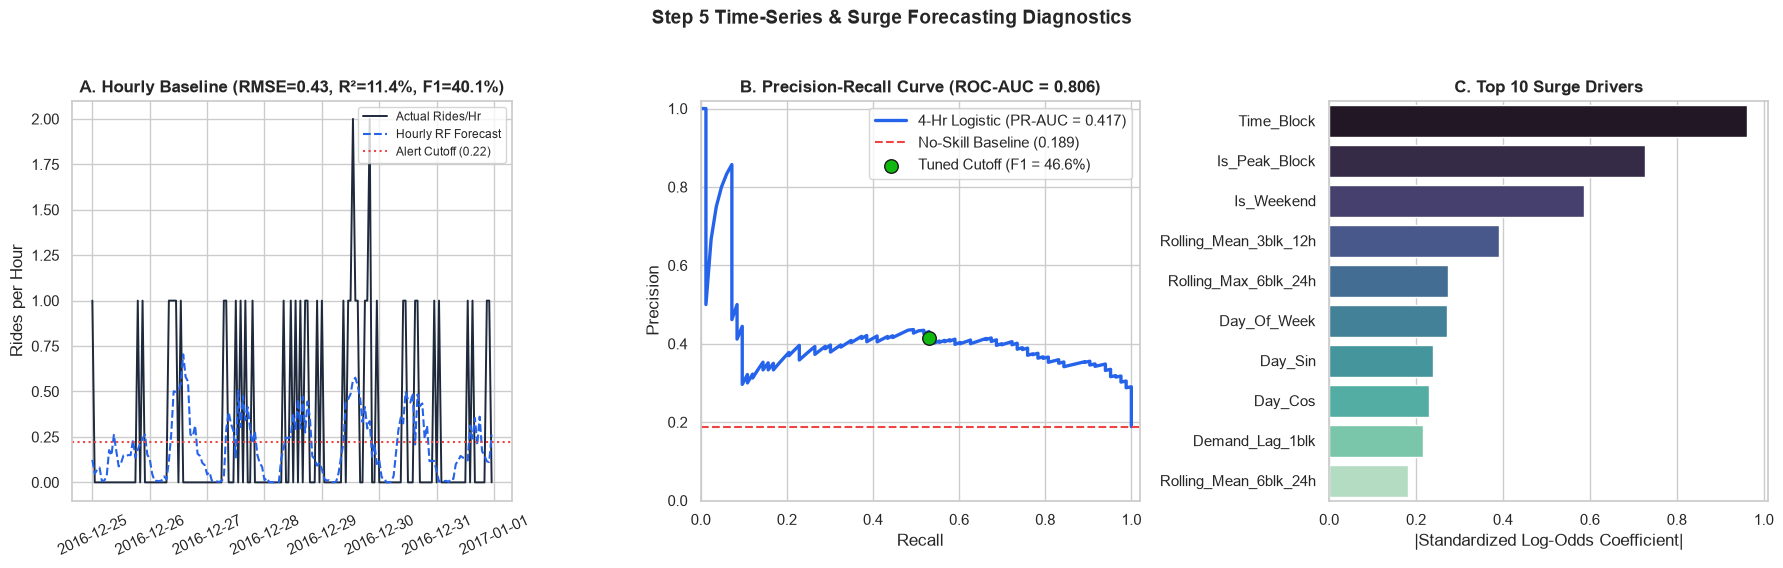

STEP FINAL COMPLETE | Surge F1: 40.05% -> 46.56% (+6.51%) | PR-AUC = 0.4174 | ROC-AUC = 0.8057


In [7]:
print("=" * 80)
print("STEP FINAL: TIME-SERIES DEMAND FORECASTING & SURGE CLASSIFICATION")
print("=" * 80)


def add_calendar_features(data, period_col, period_max):
    out = data.copy()
    out["Day_Of_Week"] = out["Request_Date"].dt.dayofweek
    out["Month"] = out["Request_Date"].dt.month
    out["Is_Weekend"] = (out["Day_Of_Week"] >= 5).astype(int)
    out["Period_Sin"] = np.sin(2 * np.pi * out[period_col] / period_max)
    out["Period_Cos"] = np.cos(2 * np.pi * out[period_col] / period_max)
    out["Day_Sin"] = np.sin(2 * np.pi * out["Day_Of_Week"] / 7.0)
    out["Day_Cos"] = np.cos(2 * np.pi * out["Day_Of_Week"] / 7.0)
    return out


def tune_f1_threshold(y_true, scores, default=0.50):
    precisions, recalls, thresholds = precision_recall_curve(y_true, scores)
    if len(thresholds) == 0:
        return default
    f1s = (2 * precisions[:-1] * recalls[:-1]) / np.maximum(precisions[:-1] + recalls[:-1], 1e-8)
    return float(thresholds[np.argmax(f1s)])


df["Request_Date"] = df["START_DATE*"].dt.floor("D")
all_dates = pd.date_range(start=df["Request_Date"].min(), end=df["Request_Date"].max(), freq="D")

# Part A: hourly demand baseline
hourly_grid = pd.MultiIndex.from_product(
    [all_dates, range(24)], names=["Request_Date", "Request Hour"]
).to_frame().reset_index(drop=True)
hr_df = pd.merge(
    hourly_grid,
    df.groupby(["Request_Date", "Request Hour"]).size().reset_index(name="Ride_Count"),
    on=["Request_Date", "Request Hour"], how="left",
).fillna({"Ride_Count": 0})
hr_df = hr_df.sort_values(["Request_Date", "Request Hour"]).reset_index(drop=True)
hr_df["Timestamp"] = hr_df["Request_Date"] + pd.to_timedelta(hr_df["Request Hour"], unit="h")
hr_df = add_calendar_features(hr_df, "Request Hour", 24.0)
hr_df["Lag_1hr"] = hr_df["Ride_Count"].shift(1).fillna(0)
hr_df["Lag_24hr"] = hr_df["Ride_Count"].shift(24).fillna(0)
hr_df["Lag_168hr"] = hr_df["Ride_Count"].shift(168).fillna(0)
hr_df["Roll_Mean_3hr"] = hr_df["Ride_Count"].shift(1).rolling(3, min_periods=1).mean().fillna(0)
hr_df["Roll_Mean_24hr"] = hr_df["Ride_Count"].shift(1).rolling(24, min_periods=1).mean().fillna(0)

hr_features = [
    "Request Hour", "Day_Of_Week", "Month", "Is_Weekend",
    "Period_Sin", "Period_Cos", "Day_Sin", "Day_Cos",
    "Lag_1hr", "Lag_24hr", "Lag_168hr", "Roll_Mean_3hr", "Roll_Mean_24hr",
]
hr_split = int(len(hr_df) * 0.80)
X_train_hr = hr_df[hr_features].iloc[:hr_split]
X_test_hr = hr_df[hr_features].iloc[hr_split:]
y_train_hr = hr_df["Ride_Count"].iloc[:hr_split]
y_test_hr = hr_df["Ride_Count"].iloc[hr_split:]
hr_test_ts = hr_df["Timestamp"].iloc[hr_split:]

hr_reg = RandomForestRegressor(n_estimators=150, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1)
hr_surge_def = round(float(y_train_hr.mean() + 2 * y_train_hr.std()), 2)
hr_val = int(len(X_train_hr) * 0.80)
hr_reg.fit(X_train_hr.iloc[:hr_val], y_train_hr.iloc[:hr_val])
best_hr_cutoff = tune_f1_threshold(
    (y_train_hr.iloc[hr_val:] >= hr_surge_def).astype(int),
    np.clip(hr_reg.predict(X_train_hr.iloc[hr_val:]), 0, None), default=0.45,
)
hr_reg.fit(X_train_hr, y_train_hr)
best_hr_preds = np.clip(hr_reg.predict(X_test_hr), 0, None)

hr_rmse = root_mean_squared_error(y_test_hr, best_hr_preds)
hr_r2 = r2_score(y_test_hr, best_hr_preds)
hr_actual_surge = (y_test_hr >= hr_surge_def).astype(int)
hr_pred_surge = (best_hr_preds >= best_hr_cutoff).astype(int)
hr_f1 = f1_score(hr_actual_surge, hr_pred_surge, zero_division=0)
hr_prec = precision_score(hr_actual_surge, hr_pred_surge, zero_division=0)
hr_rec = recall_score(hr_actual_surge, hr_pred_surge, zero_division=0)
hr_bal_acc = balanced_accuracy_score(hr_actual_surge, hr_pred_surge)
hr_pr_auc = average_precision_score(hr_actual_surge, best_hr_preds)

# Part B: 4-hour surge classifier
df["Time_Block"] = df["Request Hour"] // 4
block_grid = pd.MultiIndex.from_product(
    [all_dates, range(6)], names=["Request_Date", "Time_Block"]
).to_frame().reset_index(drop=True)
ts_df = pd.merge(
    block_grid,
    df.groupby(["Request_Date", "Time_Block"]).size().reset_index(name="Ride_Count"),
    on=["Request_Date", "Time_Block"], how="left",
).fillna({"Ride_Count": 0})
ts_df = ts_df.sort_values(["Request_Date", "Time_Block"]).reset_index(drop=True)
ts_df["Timestamp"] = ts_df["Request_Date"] + pd.to_timedelta(ts_df["Time_Block"] * 4, unit="h")
ts_df = add_calendar_features(ts_df, "Time_Block", 6.0)
ts_df["Is_Peak_Block"] = ts_df["Time_Block"].isin([2, 3, 4]).astype(int)
ts_df["Demand_Lag_1blk"] = ts_df["Ride_Count"].shift(1).fillna(0)
ts_df["Demand_Lag_2blk"] = ts_df["Ride_Count"].shift(2).fillna(0)
ts_df["Demand_Lag_6blk_24h"] = ts_df["Ride_Count"].shift(6).fillna(0)
ts_df["Demand_Lag_42blk_7d"] = ts_df["Ride_Count"].shift(42).fillna(0)
ts_df["Rolling_Mean_3blk_12h"] = ts_df["Ride_Count"].shift(1).rolling(3, min_periods=1).mean().fillna(0)
ts_df["Rolling_Mean_6blk_24h"] = ts_df["Ride_Count"].shift(1).rolling(6, min_periods=1).mean().fillna(0)
ts_df["Rolling_Max_6blk_24h"] = ts_df["Ride_Count"].shift(1).rolling(6, min_periods=1).max().fillna(0)

ts_features = [
    "Time_Block", "Day_Of_Week", "Month", "Is_Weekend", "Is_Peak_Block",
    "Period_Sin", "Period_Cos", "Day_Sin", "Day_Cos",
    "Demand_Lag_1blk", "Demand_Lag_2blk", "Demand_Lag_6blk_24h", "Demand_Lag_42blk_7d",
    "Rolling_Mean_3blk_12h", "Rolling_Mean_6blk_24h", "Rolling_Max_6blk_24h",
]
split_idx = int(len(ts_df) * 0.80)
train_df, test_df = ts_df.iloc[:split_idx], ts_df.iloc[split_idx:]
surge_cutoff_rides = max(2, int(np.ceil(train_df["Ride_Count"].quantile(0.75))))
X_train_clf = train_df[ts_features]
X_test_clf = test_df[ts_features]
y_train_clf = (train_df["Ride_Count"] >= surge_cutoff_rides).astype(int)
y_test_clf = (test_df["Ride_Count"] >= surge_cutoff_rides).astype(int)

best_clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=1.0, max_iter=500, random_state=42))
val_split = int(len(X_train_clf) * 0.80)
best_clf.fit(X_train_clf.iloc[:val_split], y_train_clf.iloc[:val_split])
best_cutoff = tune_f1_threshold(
    y_train_clf.iloc[val_split:],
    best_clf.predict_proba(X_train_clf.iloc[val_split:])[:, 1], default=0.50,
)
best_clf.fit(X_train_clf, y_train_clf)
best_probs = best_clf.predict_proba(X_test_clf)[:, 1]
final_surge_preds = (best_probs >= best_cutoff).astype(int)

pr_auc_win = average_precision_score(y_test_clf, best_probs)
roc_auc_win = roc_auc_score(y_test_clf, best_probs)
bal_acc_win = balanced_accuracy_score(y_test_clf, final_surge_preds)
prec_win = precision_score(y_test_clf, final_surge_preds, zero_division=0)
rec_win = recall_score(y_test_clf, final_surge_preds, zero_division=0)
f1_win = f1_score(y_test_clf, final_surge_preds, zero_division=0)
baseline_pr_auc = y_test_clf.mean()

impact_df = pd.DataFrame([
    {
        "Pipeline Architecture": "1. Hourly Demand Regression (Baseline)",
        "Grid Resolution": f"{len(hr_df):,} hrs (1-hr)",
        "Zero-Slot Sparsity": f"{(hr_df['Ride_Count'] == 0).mean()*100:.1f}%",
        "Selected Model": "Random Forest Regressor",
        "PR-AUC (vs Baseline)": f"{hr_pr_auc:.4f} (vs {hr_actual_surge.mean():.4f})",
        "Balanced Accuracy": f"{hr_bal_acc*100:.2f}%",
        "Precision": f"{hr_prec*100:.2f}%",
        "Recall": f"{hr_rec*100:.2f}%",
        "Surge F1-Score": f"{hr_f1*100:.2f}%",
    },
    {
        "Pipeline Architecture": "2. 4-Hour Block Surge Classifier (Final)",
        "Grid Resolution": f"{len(ts_df):,} blocks (4-hr)",
        "Zero-Slot Sparsity": f"{(ts_df['Ride_Count'] == 0).mean()*100:.1f}%",
        "Selected Model": "Logistic Regression (Balanced)",
        "PR-AUC (vs Baseline)": f"{pr_auc_win:.4f} (vs {baseline_pr_auc:.4f})",
        "Balanced Accuracy": f"{bal_acc_win*100:.2f}%",
        "Precision": f"{prec_win*100:.2f}%",
        "Recall": f"{rec_win*100:.2f}%",
        "Surge F1-Score": f"{f1_win*100:.2f}%",
    },
])
display(impact_df)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle("Step 5 Time-Series & Surge Forecasting Diagnostics", fontsize=14, fontweight="bold", y=1.03)

win_hr = min(168, len(y_test_hr))
axes[0].plot(hr_test_ts.iloc[-win_hr:], y_test_hr.iloc[-win_hr:], color="#1e293b", linewidth=1.4, label="Actual Rides/Hr")
axes[0].plot(hr_test_ts.iloc[-win_hr:], best_hr_preds[-win_hr:], color="#2563eb", linestyle="--", linewidth=1.5, label="Hourly RF Forecast")
axes[0].axhline(best_hr_cutoff, color="#ef4444", linestyle=":", linewidth=1.5, label=f"Alert Cutoff ({best_hr_cutoff:.2f})")
axes[0].set_title(f"A. Hourly Baseline (RMSE={hr_rmse:.2f}, R²={hr_r2*100:.1f}%, F1={hr_f1*100:.1f}%)", fontweight="bold")
axes[0].set_ylabel("Rides per Hour")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(loc="upper right", fontsize=8.5)

prec_curve, rec_curve, _ = precision_recall_curve(y_test_clf, best_probs)
axes[1].plot(rec_curve, prec_curve, color="#2563eb", linewidth=2.4, label=f"4-Hr Logistic (PR-AUC = {pr_auc_win:.3f})")
axes[1].axhline(baseline_pr_auc, color="#ef4444", linestyle="--", linewidth=1.5, label=f"No-Skill Baseline ({baseline_pr_auc:.3f})")
axes[1].scatter([rec_win], [prec_win], color="#10b910", s=95, zorder=5, edgecolor="k", label=f"Tuned Cutoff (F1 = {f1_win*100:.1f}%)")
axes[1].set_title(f"B. Precision-Recall Curve (ROC-AUC = {roc_auc_win:.3f})", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim(0, 1.02)
axes[1].set_ylim(0, 1.02)
axes[1].legend(loc="upper right")

imp = pd.Series(np.abs(best_clf.steps[-1][1].coef_[0]), index=ts_features).sort_values(ascending=False).head(10)
sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette="mako", legend=False, ax=axes[2])
axes[2].set_title("C. Top 10 Surge Drivers", fontweight="bold")
axes[2].set_xlabel("|Standardized Log-Odds Coefficient|")
axes[2].set_ylabel("")
plt.tight_layout()
plt.show()

print("=" * 80)
print(
    f"STEP FINAL COMPLETE | Surge F1: {hr_f1*100:.2f}% -> {f1_win*100:.2f}% "
    f"(+{(f1_win-hr_f1)*100:.2f}%) | PR-AUC = {pr_auc_win:.4f} | ROC-AUC = {roc_auc_win:.4f}"
)
print("=" * 80)